In [1]:
                ############### DECISION TREE - REGRESSION KRIGING ###############

In [3]:
########## 1. Installing and Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import KFold
#from pykrige.ok import OrdinaryKriging
from pykrige.uk import UniversalKriging

# Set random seed for reproducibility
np.random.seed(42)

In [4]:
################ 2. Loading the dataset
data = pd.read_csv('E:/VData/SData/Wells4.csv')

In [5]:
data.head()

,x_coord,y_coord,Depth,pH,SO4,NO3,T
0,17.74,15.57,259.0,7.00,39.0,9.0,27.0
1,17.48,15.82,220.0,6.60,17.0,12.0,34.7
2,17.48,15.83,220.0,6.00,925.0,5.0,27.0
3,17.39,15.37,286.0,7.00,3300.0,1.0,29.0
4,17.35,13.80,47.0,7.45,13.0,0.2,26.5


In [6]:
data.describe()

,x_coord,y_coord,Depth,pH,SO4,NO3,T
count,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000,1311.000000
mean,15.499214,13.761732,49.371823,7.047918,49.873158,6.258383,28.451777
std,0.536874,0.508679,19.132128,0.618476,146.064968,15.023649,2.827740
min,13.930000,12.270000,15.400000,4.000000,0.000000,0.000000,10.000000
25%,15.230000,13.440000,38.000000,6.730000,9.000000,1.300000,27.000000
50%,15.480000,13.780000,48.000000,7.000000,18.000000,2.800000,29.000000
75%,15.730000,14.125000,56.000000,7.375000,35.000000,7.000000,30.000000
max,17.740000,15.830000,286.000000,10.800000,3300.000000,278.000000,35.100000


In [7]:
############# 3. Data Preparation

In [8]:
# a. Target
y = data['pH']

In [9]:
# b. Features
X = data[['T', 'Depth']]

In [10]:
# c. Coords
coords = data[['x_coord', 'y_coord']]

In [11]:
# d. Splitting the dataset into training and testing datasets
X_train, X_test, y_train, y_test, coords_train, coords_test = train_test_split(X, y, coords, test_size = 0.3, random_state = 42)

In [12]:
############# 4.Fitting the Decision Tree (Trend) Model)


In [13]:
# a. Initializing the model 
dt_model = DecisionTreeRegressor(max_depth = 2, min_samples_split = 15, min_samples_leaf = 7, random_state = 42)

In [14]:
# Fiting the model
dt_model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,2
,min_samples_split,15
,min_samples_leaf,7
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [15]:
# b. # Predicting the deterministic component
y_train_pred_dt = dt_model.predict(X_train) # On the training dataset
y_test_pred_dt = dt_model.predict(X_test) # On the testing dataset

In [16]:
# c. Computing the training and testing residuals (observed - predicted trend)
train_residuals = y_train - y_train_pred_dt
test_residuals = y_test - y_test_pred_dt

In [17]:
############### 5. Peforming the Universal Kriging on training Residuals 

In [18]:
# a Universal Kriging
UK = UniversalKriging(
    x = coords_train['x_coord'].values,
    y = coords_train['y_coord'].values,
    z = train_residuals.values,
    variogram_model = 'gaussian', 
    verbose = False,
    enable_plotting = False
)

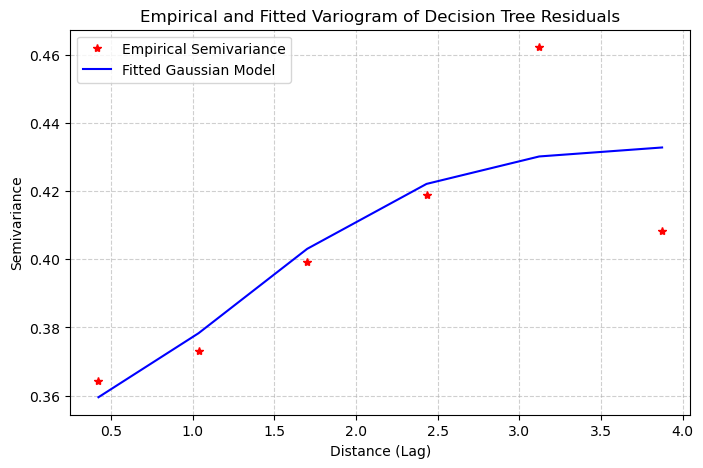

In [19]:
############### 6. Ploting the Experimental and Fitted Variogram
plt.figure(figsize = (8, 5))
plt.plot(UK.lags, UK.semivariance, 'r*', label='Empirical Semivariance')
plt.plot(UK.lags, UK.variogram_function(UK.variogram_model_parameters, UK.lags), 'b-', label = 'Fitted Gaussian Model')
plt.title('Empirical and Fitted Variogram of Decision Tree Residuals')
plt.xlabel('Distance (Lag)')
plt.ylabel('Semivariance')
plt.legend()
plt.grid(True, linestyle = '--', alpha = 0.6)
plt.show()


In [18]:
########### 7. Predicting the Residuals via Kriging

In [20]:
# a Predicting the residuals
krig_train_res, _ = UK.execute('points', coords_train['x_coord'].values, coords_train['y_coord'].values) # Training residuals
krig_test_res, _ = UK.execute('points', coords_test['x_coord'].values, coords_test['y_coord'].values) # Testing residuals

In [21]:
# b. Final Regression Kriging predictions (Trend + Residual)
y_train_pred_rk = y_train_pred_dt + krig_train_res
y_test_pred_rk = y_test_pred_dt + krig_test_res

In [22]:
############ # 8. Model Performance Evaluation

In [22]:
# a. Function Definition
def evaluate_metrics(y_true, y_pred, set_name = "Data"):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return {'Model': set_name, 'R2': r2, 'RMSE': rmse, 'MAE': mae}

In [23]:
# b. Computing the metrics for DT alone vs. Decision Tree + Kriging (RK)
results = [
    evaluate_metrics(y_train, y_train_pred_dt, "Training (DT Only)"),
    evaluate_metrics(y_test, y_test_pred_dt, "Testing (DT Only)"),
    evaluate_metrics(y_train, y_train_pred_rk, "Training (DT+RK)"),
    evaluate_metrics(y_test, y_test_pred_rk, "Testing (DT+RK)"),
]

In [24]:
# c. Displaying the Results Table
results_df = pd.DataFrame(results)
print("=== Model Performance Comparison ===")
print(results_df.to_string(index = False))

=== Model Performance Comparison ===
             Model        R2     RMSE      MAE
Training (DT Only)  0.082933 0.611619 0.431513
 Testing (DT Only) -0.052990 0.581118 0.430981
  Training (DT+RK)  0.852704 0.245119 0.062116
   Testing (DT+RK) -0.065653 0.584602 0.420915


In [67]:
############## 9. Parity Plot Visualization (Actual vs Predicted)

In [25]:
# 5. Evaluate Metrics (R², RMSE, MAE)
# ==========================================
def calculate_metrics(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return r2, rmse, mae

In [26]:
# The metrics
r2_train, rmse_train, mae_train = calculate_metrics(y_train, y_train_pred_rk)
r2_test, rmse_test, mae_test = calculate_metrics(y_test, y_test_pred_rk)

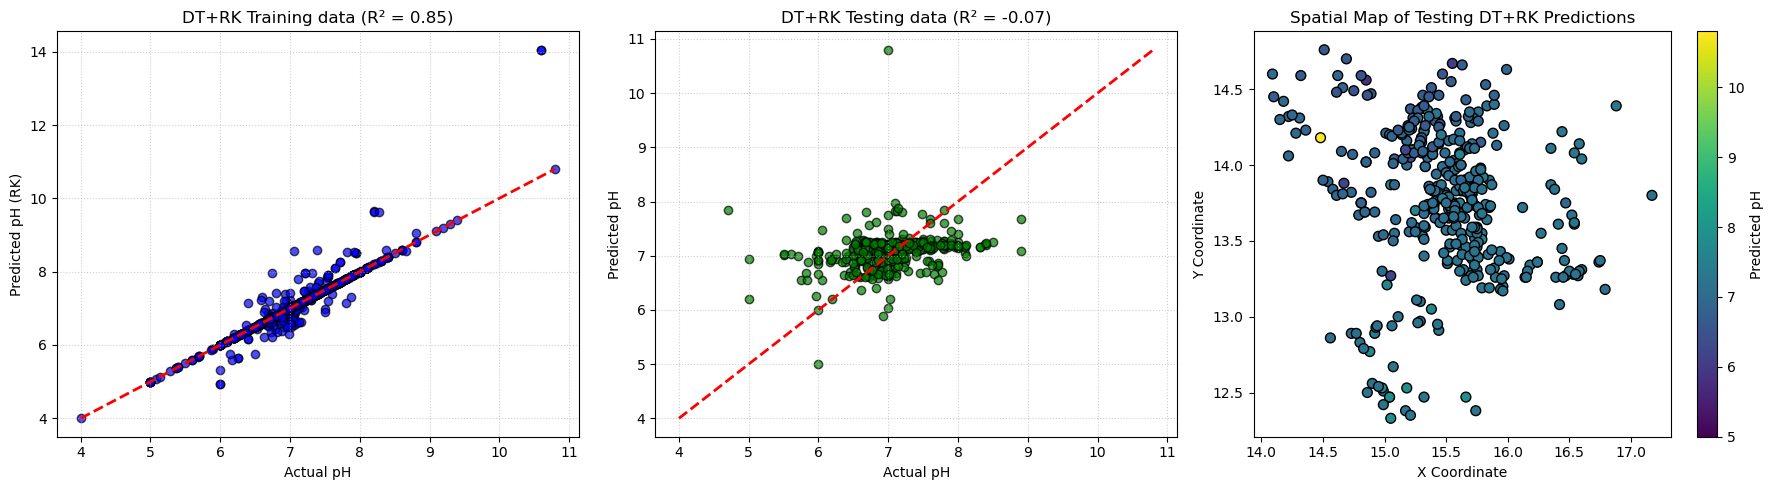

In [28]:
fig, axes = plt.subplots(1, 3, figsize = (18, 5))

# Plot 1: Train Actual vs Predicted
axes[0].scatter(y_train, y_train_pred_rk, alpha = 0.7, color = 'blue', edgecolor = 'k')
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw = 2)
axes[0].set_title(f"DT+RK Training data (R² = {r2_train:.2f})")
axes[0].set_xlabel("Actual pH")
axes[0].set_ylabel("Predicted pH (RK)")
axes[0].grid(True, linestyle = ':', alpha = 0.6)

# Plot 2: Test Actual vs Predicted
axes[1].scatter(y_test, y_test_pred_rk, alpha = 0.7, color = 'green', edgecolor = 'k')
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw = 2)
axes[1].set_title(f"DT+RK Testing data (R² = {r2_test:.2f})")
axes[1].set_xlabel("Actual pH")
axes[1].set_ylabel("Predicted pH")
axes[1].grid(True, linestyle = ':', alpha = 0.6)

# Plot 3: Spatial Map of Test Predictions
sc = axes[2].scatter(coords_test['x_coord'], coords_test['y_coord'], c = y_test_pred_rk, cmap = 'viridis', s = 50, edgecolor='k')
axes[2].set_title("Spatial Map of Testing DT+RK Predictions")
axes[2].set_xlabel("X Coordinate")
axes[2].set_ylabel("Y Coordinate")
cbar = plt.colorbar(sc, ax = axes[2])
cbar.set_label("Predicted pH")

plt.tight_layout()
plt.show()

In [29]:
################ 9. K-Fold Cross-Validation

In [31]:
# 1. Data 

In [30]:
# Target
y = data['pH']

In [31]:
# b. Features
X = data[['T', 'Depth']]

In [32]:
# c. Coords
coords = data[['x_coord', 'y_coord']]

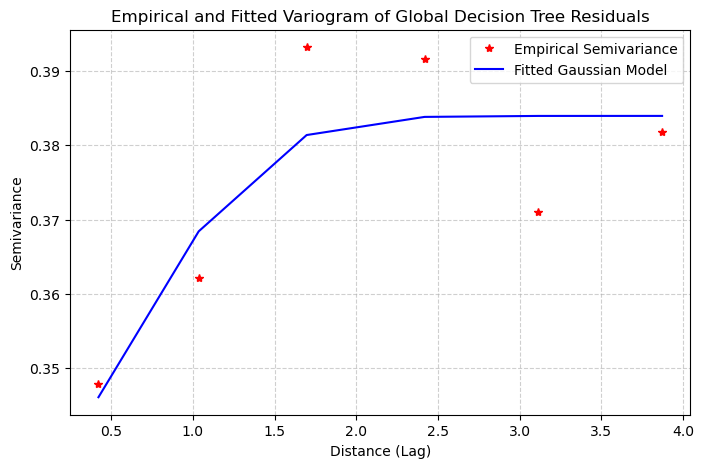

In [35]:
# 2. Ploting the Variogram (Using Full the Dataset for Demonstration)
# Fit a global tree to get global residuals for variogram inspection
global_dt = DecisionTreeRegressor(max_depth = 2, min_samples_split = 15, min_samples_leaf = 7, random_state = 42)
global_dt.fit(X, y)
global_residuals = y - global_dt.predict(X)

UK_global = UniversalKriging(
    x = coords['x_coord'].values,
    y = coords['y_coord'].values,
    z = global_residuals.values,
    variogram_model = 'gaussian',
    verbose= False,
    enable_plotting = False
)

plt.figure(figsize=(8, 5))
plt.plot(UK_global.lags, UK_global.semivariance, 'r*', label = 'Empirical Semivariance')
plt.plot(UK_global.lags, UK_global.variogram_function(UK_global.variogram_model_parameters, UK_global.lags), 'b-', label= 'Fitted Gaussian Model')
plt.title('Empirical and Fitted Variogram of Global Decision Tree Residuals')
plt.xlabel('Distance (Lag)')
plt.ylabel('Semivariance')
plt.legend()
plt.grid(True, linestyle='--', alpha = 0.6)
plt.show()

In [36]:
#### # 3. K-Fold Cross-Validation Loop
n_splits = 5
kf = KFold(n_splits = n_splits, shuffle = True, random_state = 42)

# Arrays to store out-of-fold (OOF) predictions
dt_oof_preds = np.zeros(len(data))
rk_oof_preds = np.zeros(len(data))

for train_idx, val_idx in kf.split(data):
    # Splitting data for the current fold
    df_train = data.iloc[train_idx]
    df_val = data.iloc[val_idx]
    
    X_tr = df_train[['T', 'Depth']]
    y_tr = df_train['pH']
    coords_tr = df_train[['x_coord', 'y_coord']]
    
    X_val = df_val[['T', 'Depth']]
    coords_val = df_val[['x_coord', 'y_coord']]
    
    # A. Fitting the Decision Tree Trend Model on Training Fold
    dt_fold = DecisionTreeRegressor(max_depth = 2, min_samples_split = 15, min_samples_leaf = 7, random_state = 42)
    dt_fold.fit(X_tr, y_tr)
    
    # Predicting the trend on validation fold
    dt_val_pred = dt_fold.predict(X_val)
    dt_oof_preds[val_idx] = dt_val_pred
    
    # Calculating residuals on training fold
    train_residuals = y_tr - dt_fold.predict(X_tr)
    
    # B. Fittting the Universal Kriging on Training Residuals
    UK_fold = UniversalKriging(
        x = coords_tr['x_coord'].values,
        y = coords_tr['y_coord'].values,
        z = train_residuals.values,
        variogram_model = 'gaussian',
        verbose = False,
        enable_plotting = False
    )
    
    # Predicting residuals for validation fold using Kriging
    krig_val_res, _ = UK_fold.execute('points', coords_val['x_coord'].values, coords_val['y_coord'].values)
    
    # Combining Trend + Kriging Residuals
    rk_oof_preds[val_idx] = dt_val_pred + krig_val_res

In [38]:
##### 4. Computing the cross-validated performance
results = [
    evaluate_metrics(y, dt_oof_preds, f"{n_splits}-Fold CV (DT Only)"),
    evaluate_metrics(y, rk_oof_preds, f"{n_splits}-Fold CV (DT+RK)")
]

In [39]:
## Printing the ressults
results_df = pd.DataFrame(results)
print(f"=== {n_splits}-Fold Cross-Validation Testing Performance Summary ===")
print(results_df.to_string(index=False))

=== 5-Fold Cross-Validation Testing Performance Summary ===
              Model       R2     RMSE      MAE
5-Fold CV (DT Only) 0.009164 0.615401 0.438958
  5-Fold CV (DT+RK) 0.131705 0.576091 0.411426


In [40]:
          ################# Training Model CV ################

In [41]:
#### # 3. K-Fold Cross-Validation Loop
n_splits = 5
kf = KFold(n_splits = n_splits, shuffle = True, random_state = 42)

# Arrays to store out-of-fold (OOF) predictions
dt_oof_preds = np.zeros(len(data))
rk_oof_preds = np.zeros(len(data))

for train_idx, val_idx in kf.split(data):
    # Split data for the current fold
    df_train = data.iloc[train_idx]
    df_val = data.iloc[val_idx]
    
    X_tr = df_train[['T', 'Depth']]
    y_tr = df_train['pH']
    coords_tr = df_train[['x_coord', 'y_coord']]
    
    X_val = df_val[['T', 'Depth']]
    coords_val = df_val[['x_coord', 'y_coord']]
    
    # A. Fitting the Decision Tree Trend Model on Training Fold
    dt_fold = DecisionTreeRegressor(max_depth = 2, min_samples_split = 15, min_samples_leaf = 7, random_state = 42)
    dt_fold.fit(X_tr, y_tr)
    
    # Predicting the trend on validation fold
    dt_tr_pred = dt_fold.predict(X_tr)
    dt_oof_preds[train_idx] = dt_tr_pred
    
    # Calculating residuals on training fold
    train_residuals = y_tr - dt_fold.predict(X_tr)
    
    # B. Fitting Universal Kriging on Training Residuals
    UK_fold = UniversalKriging(
        x = coords_tr['x_coord'].values,
        y = coords_tr['y_coord'].values,
        z = train_residuals.values,
        variogram_model = 'gaussian',
        verbose = False,
        enable_plotting = False
    )
    
    # Predicting residuals on the training fold using Kriging
    krig_tr_res, _ = UK_fold.execute('points', coords_tr['x_coord'].values, coords_tr['y_coord'].values)
    
    # Combining Trend + Kriging Residuals
    rk_oof_preds[train_idx] = dt_tr_pred + krig_tr_res

In [42]:
##### 4. Calculating the cross-validated performance
results = [
    evaluate_metrics(y, dt_oof_preds, f"{n_splits}-Fold CV (DT Only)"),
    evaluate_metrics(y, rk_oof_preds, f"{n_splits}-Fold CV (DT+RK)")
]

In [43]:
## Printing the ressults
results_df = pd.DataFrame(results)
print(f"=== {n_splits}-Fold Cross-Validation Training Performance Summary ===")
print(results_df.to_string(index = False))

=== 5-Fold Cross-Validation Training Performance Summary ===
              Model       R2     RMSE      MAE
5-Fold CV (DT Only) 0.065685 0.597591 0.427344
  5-Fold CV (DT+RK) 0.885230 0.209446 0.067010
